In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

print(os.listdir('/content/drive/MyDrive'))

['Classroom', 'CO1_Fundamentals of Computers_Lecture1.gdoc', 'FSWD_Activity Set#1_HTML.docx', 'CO2_Intro_to_C_Lecture2&3.gdoc', 'Colab Notebooks', 'DS_CA_Session1 (3).1_RVU.gdoc', 'DS_CA_Session1 (2).1_RVU.gdoc', 'DS_CA_Session1 (1).1_RVU.gdoc', 'DS_CA_Session1.1_RVU.gdoc', 'C03As2P4.c', 'Co-4 and Co-5.pptx', 'Untitled document (3).gdoc', 'Untitled document (2).gdoc', 'Charging and Discharging of a capacitor in a RC circuit.gdoc', 'Untitled document (1).gdoc', 'Practise (1).c', 'Practise.c', 'Project presentation  template.pptx', 'Circuitrix-Light Up RVU-Fisrt slide format.gslides', 'Co-1 and Co-2.gslides', 'Co-3 (1).gslides', 'Section-B.gdoc', '_Circuitrix-Light_Up_RVU-Fisrt_slide_format[1][1][1][1] (5).pptx', '_Circuitrix-Light_Up_RVU-Fisrt_slide_format[1][1][1][1] (4).pptx', '_Circuitrix-Light_Up_RVU-Fisrt_slide_format[1][1][1][1] (3).pptx', '_Circuitrix-Light_Up_RVU-Fisrt_slide_format[1][1][1][1] (2).pptx', '_Circuitrix-Light_Up_RVU-Fisrt_slide_format[1][1][1][1] (1).pptx', '_Circu

In [ ]:
import os
import numpy as np
import librosa
from tqdm import tqdm

In [ ]:
import os

dataset_path = "/content/drive/MyDrive/IEMOCAP dataset"

print("Top level folders:")
print(os.listdir(dataset_path))

Top level folders:
['IEMOCAP_full_release_withoutVideos.tar.gz', 'IEMOCAP_X_all.npy', 'IEMOCAP_y_all.npy']


In [ ]:
!tar -xvzf "/content/drive/MyDrive/IEMOCAP dataset/IEMOCAP_full_release_withoutVideos.tar.gz" -C /content/

Streaming output truncated to the last 5000 lines.
IEMOCAP_full_release/Session5/sentences/MOCAP_rotated/Ses05F_script03_1/Ses05F_script03_1_M030.txt
IEMOCAP_full_release/Session5/sentences/MOCAP_rotated/Ses05F_script03_1/Ses05F_script03_1_M021.txt
IEMOCAP_full_release/Session5/sentences/MOCAP_rotated/Ses05F_script03_1/Ses05F_script03_1_F007.txt
IEMOCAP_full_release/Session5/sentences/MOCAP_rotated/Ses05F_script03_1/Ses05F_script03_1_F003.txt
IEMOCAP_full_release/Session5/sentences/MOCAP_rotated/Ses05F_script03_1/Ses05F_script03_1_M033.txt
IEMOCAP_full_release/Session5/sentences/MOCAP_rotated/Ses05F_script03_1/Ses05F_script03_1_F013.txt
IEMOCAP_full_release/Session5/sentences/MOCAP_rotated/Ses05F_script03_1/Ses05F_script03_1_F022.txt
IEMOCAP_full_release/Session5/sentences/MOCAP_rotated/Ses05F_script03_1/Ses05F_script03_1_M012.txt
IEMOCAP_full_release/Session5/sentences/MOCAP_rotated/Ses05F_script03_1/Ses05F_script03_1_M016.txt
IEMOCAP_full_release/Session5/sentences/MOCAP_rotated/Ses0

In [ ]:
dataset_path = "/content/IEMOCAP_full_release"

In [ ]:
# ==============================================
# 🔥 LOAD IEMOCAP DATA (AUDIO + TEXT + LABELS)
# ==============================================

import os
import glob

DATA_PATH = "/content/IEMOCAP_full_release"

valid_emotions = ["ang", "hap", "sad", "neu", "exc"]

wav_paths = []
transcripts = []
labels = []

for session in range(1, 6):
    session_path = os.path.join(DATA_PATH, f"Session{session}")

    # Get all wav files
    wav_files = glob.glob(os.path.join(session_path, "**/*.wav"), recursive=True)

    for wav_file in wav_files:
        file_id = os.path.basename(wav_file).replace(".wav", "")
        parts = file_id.split("_")

        # Emotion annotation file
        if "impro" in file_id:
            ann_name = "_".join(parts[:2]) + ".txt"
        else:
            ann_name = "_".join(parts[:3]) + ".txt"

        ann_path = os.path.join(session_path, "dialog", "EmoEvaluation", ann_name)

        # Transcript file
        trans_path = os.path.join(session_path, "dialog", "transcriptions", ann_name)

        if not os.path.exists(ann_path) or not os.path.exists(trans_path):
            continue

        # -----------------------------
        # GET EMOTION LABEL
        # -----------------------------
        emotion = None
        with open(ann_path) as f:
            for line in f:
                if file_id in line:
                    emotion = line.strip().split()[4]
                    break

        if emotion not in valid_emotions:
            continue

        if emotion == "exc":
            emotion = "hap"

        # -----------------------------
        # GET TRANSCRIPT
        # -----------------------------
        text = ""
        with open(trans_path) as f:
            for line in f:
                if file_id in line:
                    text = " ".join(line.strip().split()[2:])
                    break

        if text == "":
            continue

        # -----------------------------
        # STORE
        # -----------------------------
        wav_paths.append(wav_file)
        transcripts.append(text)
        labels.append(emotion)

print("✅ Total samples:", len(wav_paths))

✅ Total samples: 5621


**Multimodal - MLP ( Audio Features - MelSpectrogram, Delta, Delta2, Text - BERT)**


✅ Total samples: 5621


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
100%|██████████| 5621/5621 [18:38<00:00,  5.03it/s]


Epoch 1, Loss: 1.2171
Epoch 2, Loss: 1.0467
Epoch 3, Loss: 0.9620
Epoch 4, Loss: 0.9065
Epoch 5, Loss: 0.8688
Epoch 6, Loss: 0.8278
Epoch 7, Loss: 0.7981
Epoch 8, Loss: 0.7616
Epoch 9, Loss: 0.7315
Epoch 10, Loss: 0.6992
Epoch 11, Loss: 0.6830
Epoch 12, Loss: 0.6544
Epoch 13, Loss: 0.6277
Epoch 14, Loss: 0.5987
Epoch 15, Loss: 0.5804
Epoch 16, Loss: 0.5819
Epoch 17, Loss: 0.5513
Epoch 18, Loss: 0.5328
Epoch 19, Loss: 0.5051
Epoch 20, Loss: 0.4959
Epoch 21, Loss: 0.4819
Epoch 22, Loss: 0.4714
Epoch 23, Loss: 0.4475
Epoch 24, Loss: 0.4373
Epoch 25, Loss: 0.4307

🔥 Accuracy: 0.5742222222222222
              precision    recall  f1-score   support

           0       0.67      0.63      0.65       223
           1       0.53      0.46      0.49       331
           2       0.52      0.55      0.54       351
           3       0.62      0.73      0.67       220

    accuracy                           0.57      1125
   macro avg       0.59      0.59      0.59      1125
weighted avg       0.5

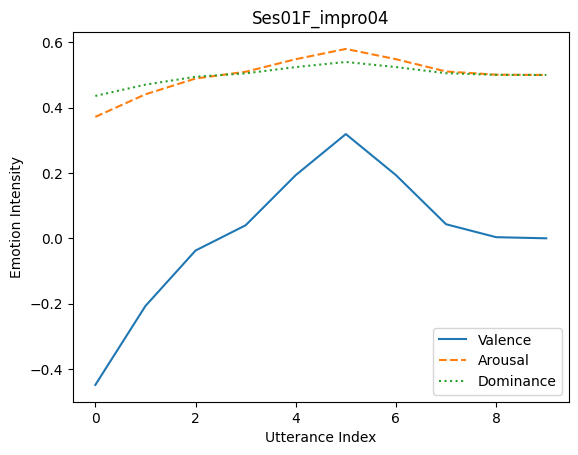


📊 CONCLUSION:
➡️ Overall Positive Emotional Shift
➡️ Emotion is Smooth


In [ ]:
# ==============================================
# 🔥 FINAL MULTIMODAL EMOTION RECOGNITION + TREND ANALYSIS
# ==============================================

!pip install librosa transformers scikit-learn -q

import os, re, glob, json
import librosa
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from tqdm import tqdm
from scipy.ndimage import gaussian_filter1d

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, classification_report
from sklearn.utils.class_weight import compute_class_weight

from transformers import BertTokenizer, BertModel

# -------------------------------------------------
# DEVICE
# -------------------------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# -------------------------------------------------
# LOAD DATA
# -------------------------------------------------
DATA_PATH = "/content/IEMOCAP_full_release"
valid_emotions = ["ang", "hap", "sad", "neu", "exc"]

wav_paths, transcripts, labels = [], [], []

for session in range(1, 6):
    session_path = os.path.join(DATA_PATH, f"Session{session}")
    wav_files = glob.glob(os.path.join(session_path, "**/*.wav"), recursive=True)

    for wav_file in wav_files:
        file_id = os.path.basename(wav_file).replace(".wav", "")
        parts = file_id.split("_")

        ann_name = "_".join(parts[:2]) + ".txt" if "impro" in file_id else "_".join(parts[:3]) + ".txt"
        ann_path = os.path.join(session_path, "dialog", "EmoEvaluation", ann_name)
        trans_path = os.path.join(session_path, "dialog", "transcriptions", ann_name)

        if not os.path.exists(ann_path) or not os.path.exists(trans_path):
            continue

        # Emotion
        emotion = None
        with open(ann_path) as f:
            for line in f:
                if file_id in line:
                    emotion = line.strip().split()[4]
                    break

        if emotion not in valid_emotions:
            continue
        if emotion == "exc":
            emotion = "hap"

        # Text
        text = ""
        with open(trans_path) as f:
            for line in f:
                if file_id in line:
                    text = " ".join(line.strip().split()[2:])
                    break

        if text == "":
            continue

        wav_paths.append(wav_file)
        transcripts.append(text)
        labels.append(emotion)

print("✅ Total samples:", len(wav_paths))

# -------------------------------------------------
# 🔥 IMPROVED AUDIO FEATURE (LOG-MEL + DELTA)
# -------------------------------------------------
def extract_audio_features(file_path, max_len=120):
    signal, sr = librosa.load(file_path, sr=16000)

    mel = librosa.feature.melspectrogram(y=signal, sr=sr, n_mels=40)
    mel_db = librosa.power_to_db(mel)

    delta = librosa.feature.delta(mel_db)
    delta2 = librosa.feature.delta(mel_db, order=2)

    feature = np.vstack([mel_db, delta, delta2])

    if feature.shape[1] < max_len:
        feature = np.pad(feature, ((0,0),(0,max_len-feature.shape[1])))
    else:
        feature = feature[:, :max_len]

    return feature.flatten()

# -------------------------------------------------
# TEXT FEATURE (BERT)
# -------------------------------------------------
tokenizer = BertTokenizer.from_pretrained("bert-base-uncased")
bert_model = BertModel.from_pretrained("bert-base-uncased").to(device)
bert_model.eval()

def extract_text_embedding(text):
    inputs = tokenizer(text, return_tensors="pt", truncation=True, padding=True).to(device)
    with torch.no_grad():
        outputs = bert_model(**inputs)
    return outputs.last_hidden_state[:,0,:].cpu().numpy().flatten()

# -------------------------------------------------
# FEATURE EXTRACTION
# -------------------------------------------------
X, y = [], []

for i in tqdm(range(len(wav_paths))):
    audio_feat = extract_audio_features(wav_paths[i])
    text_feat = extract_text_embedding(transcripts[i])

    X.append(np.concatenate([audio_feat, text_feat]))
    y.append(labels[i])

X = np.array(X)
y = np.array(y)

# -------------------------------------------------
# ENCODING
# -------------------------------------------------
le = LabelEncoder()
y = le.fit_transform(y)

# -------------------------------------------------
# SPLIT (IMPORTANT FIX INCLUDED)
# -------------------------------------------------
X_train, X_test, y_train, y_test, paths_train, paths_test = train_test_split(
    X, y, wav_paths, test_size=0.2, stratify=y, random_state=42
)

# -------------------------------------------------
# NORMALIZATION + PCA
# -------------------------------------------------
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

pca = PCA(n_components=120)
X_train = pca.fit_transform(X_train)
X_test = pca.transform(X_test)

# -------------------------------------------------
# CLASS WEIGHTS
# -------------------------------------------------
cw = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
cw = torch.tensor(cw, dtype=torch.float32).to(device)

# -------------------------------------------------
# MODEL
# -------------------------------------------------
class EmotionMLP(nn.Module):
    def __init__(self, input_size, num_classes):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_size, 512),
            nn.ReLU(),
            nn.BatchNorm1d(512),
            nn.Dropout(0.4),

            nn.Linear(512, 256),
            nn.ReLU(),
            nn.BatchNorm1d(256),
            nn.Dropout(0.3),

            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        return self.net(x)

model = EmotionMLP(X_train.shape[1], len(np.unique(y))).to(device)

# -------------------------------------------------
# TRAINING
# -------------------------------------------------
train_loader = torch.utils.data.DataLoader(
    torch.utils.data.TensorDataset(
        torch.tensor(X_train, dtype=torch.float32),
        torch.tensor(y_train)
    ),
    batch_size=32,
    shuffle=True
)

test_loader = torch.utils.data.DataLoader(
    torch.utils.data.TensorDataset(
        torch.tensor(X_test, dtype=torch.float32),
        torch.tensor(y_test)
    ),
    batch_size=32
)

criterion = nn.CrossEntropyLoss(weight=cw)
optimizer = torch.optim.Adam(model.parameters(), lr=3e-4)

for epoch in range(25):
    model.train()
    total_loss = 0

    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)

        preds = model(xb)
        loss = criterion(preds, yb)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(f"Epoch {epoch+1}, Loss: {total_loss/len(train_loader):.4f}")

# -------------------------------------------------
# EVALUATION
# -------------------------------------------------
model.eval()
all_preds = []

with torch.no_grad():
    for xb, _ in test_loader:
        xb = xb.to(device)
        preds = torch.argmax(model(xb), dim=1)
        all_preds.extend(preds.cpu().numpy())

print("\n🔥 Accuracy:", accuracy_score(y_test, all_preds))
print(classification_report(y_test, all_preds))

pred_labels = le.inverse_transform(all_preds)

# -------------------------------------------------
# 📊 EMOTION TREND ANALYSIS
# -------------------------------------------------
records = []

for idx, (path, pred) in enumerate(zip(paths_test, pred_labels)):
    filename = os.path.basename(path).replace(".wav", "")
    parts = filename.split("_")

    conv_id = "_".join(parts[:2])
    match = re.search(r'(\d+)$', filename)
    utt_id = int(match.group(1)) if match else idx

    records.append({
        "conversation_id": conv_id,
        "utterance_id": utt_id,
        "emotion_label": pred
    })

df = pd.DataFrame(records).sort_values(by=["conversation_id","utterance_id"])

# -------------------------------------------------
# VAD MAP
# -------------------------------------------------
VAD_MAP = {
    "hap": (0.8,0.7,0.6),
    "sad": (-0.7,0.3,0.4),
    "ang": (-0.6,0.8,0.7),
    "neu": (0.0,0.5,0.5)
}

os.makedirs("plots", exist_ok=True)

# -------------------------------------------------
# PROCESS ALL CONVERSATIONS
# -------------------------------------------------
for cid, grp in df.groupby("conversation_id"):

    emotions = grp["emotion_label"].tolist()
    vad = np.array([VAD_MAP[e] for e in emotions])

    val = gaussian_filter1d(vad[:,0],1)
    aro = gaussian_filter1d(vad[:,1],1)
    dom = gaussian_filter1d(vad[:,2],1)

    plt.figure()
    x = range(len(val))

    plt.plot(x, val, label="Valence")
    plt.plot(x, aro, linestyle="--", label="Arousal")
    plt.plot(x, dom, linestyle=":", label="Dominance")

    plt.xlabel("Utterance Index")
    plt.ylabel("Emotion Intensity")
    plt.title(cid)
    plt.legend()

    plt.savefig(f"plots/{cid}.png")
    plt.close()

# -------------------------------------------------
# 🎯 USER QUERY + CONCLUSION
# -------------------------------------------------
print("\nSample Conversation IDs:")
print(df["conversation_id"].unique()[:10])

cid = input("\nEnter conversation ID: ")

subset = df[df["conversation_id"] == cid]

if len(subset) > 0:
    emotions = subset["emotion_label"].tolist()
    vad = np.array([VAD_MAP[e] for e in emotions])

    val = gaussian_filter1d(vad[:,0],1)
    aro = gaussian_filter1d(vad[:,1],1)
    dom = gaussian_filter1d(vad[:,2],1)

    plt.figure()
    x = range(len(val))

    plt.plot(x, val, label="Valence")
    plt.plot(x, aro, linestyle="--", label="Arousal")
    plt.plot(x, dom, linestyle=":", label="Dominance")

    plt.xlabel("Utterance Index")
    plt.ylabel("Emotion Intensity")
    plt.title(cid)
    plt.legend()
    plt.show()

    # ✅ CONCLUSION
    trend = val[-1] - val[0]
    variance = np.var(val)

    print("\n📊 CONCLUSION:")

    if trend > 0.2:
        print("➡️ Overall Positive Emotional Shift")
    elif trend < -0.2:
        print("➡️ Overall Negative Emotional Shift")
    else:
        print("➡️ Emotion is Stable")

    if variance > 0.5:
        print("➡️ High Emotional Fluctuation")
    else:
        print("➡️ Emotion is Smooth")

else:
    print("❌ Conversation ID not found")

**Multimodal - MLP ( Audio Features - MelSpectrogram, Chroma, ZCR, Text - TF-IDF+SVD)**

✅ Samples: 5621


100%|██████████| 5621/5621 [07:36<00:00, 12.32it/s]


Epoch 1, Loss: 1.0372
Epoch 2, Loss: 0.7328
Epoch 3, Loss: 0.5997
Epoch 4, Loss: 0.5309
Epoch 5, Loss: 0.4660
Epoch 6, Loss: 0.4272
Epoch 7, Loss: 0.3861
Epoch 8, Loss: 0.3556
Epoch 9, Loss: 0.3329
Epoch 10, Loss: 0.3178
Epoch 11, Loss: 0.2818
Epoch 12, Loss: 0.2747
Epoch 13, Loss: 0.2647
Epoch 14, Loss: 0.2395
Epoch 15, Loss: 0.2246
Epoch 16, Loss: 0.2165
Epoch 17, Loss: 0.2257
Epoch 18, Loss: 0.2065
Epoch 19, Loss: 0.1959
Epoch 20, Loss: 0.1737
Epoch 21, Loss: 0.1919
Epoch 22, Loss: 0.1791
Epoch 23, Loss: 0.1629
Epoch 24, Loss: 0.1693
Epoch 25, Loss: 0.1681
Epoch 26, Loss: 0.1572
Epoch 27, Loss: 0.1504
Epoch 28, Loss: 0.1627
Epoch 29, Loss: 0.1601
Epoch 30, Loss: 0.1549

🔥 Accuracy: 0.7137777777777777
              precision    recall  f1-score   support

           0       0.79      0.79      0.79       223
           1       0.75      0.70      0.73       331
           2       0.65      0.67      0.66       351
           3       0.70      0.72      0.71       220

    accuracy   

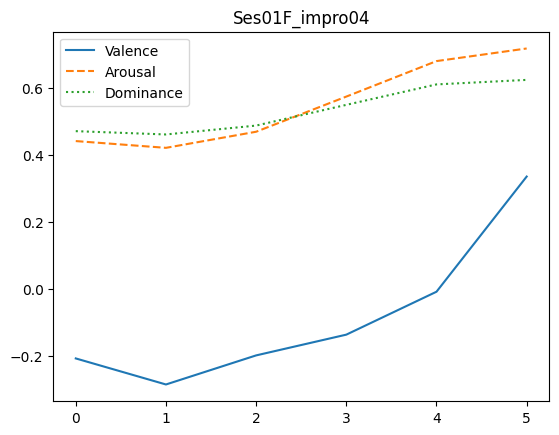


📊 CONCLUSION:
➡️ Positive Shift
➡️ Stable Behavior


In [ ]:
# ==============================================
# 🔥 FINAL MULTIMODAL (NO WAV2VEC / NO BERT)
# ==============================================

!pip install librosa scikit-learn -q

import os, re, glob, json
import numpy as np
import pandas as pd
import librosa
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from tqdm import tqdm
from scipy.ndimage import gaussian_filter1d

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from sklearn.utils.class_weight import compute_class_weight
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD

# -------------------------------------------------
# DEVICE
# -------------------------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# -------------------------------------------------
# LOAD DATA
# -------------------------------------------------
DATA_PATH = "/content/IEMOCAP_full_release"
valid_emotions = ["ang","hap","sad","neu","exc"]

wav_paths, texts, labels = [], [], []

for session in range(1,6):
    session_path = os.path.join(DATA_PATH, f"Session{session}")
    wav_files = glob.glob(os.path.join(session_path, "**/*.wav"), recursive=True)

    for wav_file in wav_files:
        file_id = os.path.basename(wav_file).replace(".wav","")
        parts = file_id.split("_")

        ann_name = "_".join(parts[:2]) + ".txt" if "impro" in file_id else "_".join(parts[:3]) + ".txt"
        ann_path = os.path.join(session_path,"dialog","EmoEvaluation",ann_name)
        trans_path = os.path.join(session_path,"dialog","transcriptions",ann_name)

        if not os.path.exists(ann_path) or not os.path.exists(trans_path):
            continue

        # emotion
        emotion = None
        with open(ann_path) as f:
            for line in f:
                if file_id in line:
                    emotion = line.strip().split()[4]
                    break

        if emotion not in valid_emotions:
            continue
        if emotion == "exc":
            emotion = "hap"

        # text
        text = ""
        with open(trans_path) as f:
            for line in f:
                if file_id in line:
                    text = " ".join(line.strip().split()[2:])
                    break

        if text == "":
            continue

        wav_paths.append(wav_file)
        texts.append(text)
        labels.append(emotion)

print("✅ Samples:", len(wav_paths))

# -------------------------------------------------
# AUDIO FEATURE EXTRACTION (STRONG)
# -------------------------------------------------
def extract_audio_features(path):
    y, sr = librosa.load(path, sr=16000)

    mel = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=40)
    mel = np.mean(mel, axis=1)

    chroma = librosa.feature.chroma_stft(y=y, sr=sr)
    chroma = np.mean(chroma, axis=1)

    spec_cent = np.mean(librosa.feature.spectral_centroid(y=y, sr=sr))
    spec_bw = np.mean(librosa.feature.spectral_bandwidth(y=y, sr=sr))
    zcr = np.mean(librosa.feature.zero_crossing_rate(y))

    return np.concatenate([mel, chroma, [spec_cent, spec_bw, zcr]])

# -------------------------------------------------
# EXTRACT AUDIO FEATURES
# -------------------------------------------------
audio_features = []

for path in tqdm(wav_paths):
    audio_features.append(extract_audio_features(path))

audio_features = np.array(audio_features)

# -------------------------------------------------
# TEXT FEATURE (TF-IDF + SVD)
# -------------------------------------------------
tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1,2,3))
X_text = tfidf.fit_transform(texts)

svd = TruncatedSVD(n_components=200)
X_text = svd.fit_transform(X_text)

# -------------------------------------------------
# ENCODING
# -------------------------------------------------
le = LabelEncoder()
y = le.fit_transform(labels)

# -------------------------------------------------
# SPLIT (IMPORTANT)
# -------------------------------------------------
Xa_train, Xa_test, Xt_train, Xt_test, y_train, y_test, paths_train, paths_test = train_test_split(
    audio_features, X_text, y, wav_paths, test_size=0.2, stratify=y, random_state=42
)

# -------------------------------------------------
# NORMALIZATION
# -------------------------------------------------
scaler_a = StandardScaler()
Xa_train = scaler_a.fit_transform(Xa_train)
Xa_test = scaler_a.transform(Xa_test)

scaler_t = StandardScaler()
Xt_train = scaler_t.fit_transform(Xt_train)
Xt_test = scaler_t.transform(Xt_test)

# -------------------------------------------------
# DATASET
# -------------------------------------------------
train_dataset = torch.utils.data.TensorDataset(
    torch.tensor(Xa_train, dtype=torch.float32),
    torch.tensor(Xt_train, dtype=torch.float32),
    torch.tensor(y_train)
)

test_dataset = torch.utils.data.TensorDataset(
    torch.tensor(Xa_test, dtype=torch.float32),
    torch.tensor(Xt_test, dtype=torch.float32),
    torch.tensor(y_test)
)

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=32)

# -------------------------------------------------
# CLASS WEIGHTS
# -------------------------------------------------
cw = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
cw = torch.tensor(cw, dtype=torch.float32).to(device)

# -------------------------------------------------
# MODEL (STRONG MLP)
# -------------------------------------------------
class FusionNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.audio_fc = nn.Sequential(
            nn.Linear(Xa_train.shape[1],128),
            nn.ReLU(),
            nn.BatchNorm1d(128)
        )

        self.text_fc = nn.Sequential(
            nn.Linear(Xt_train.shape[1],128),
            nn.ReLU(),
            nn.BatchNorm1d(128)
        )

        self.classifier = nn.Sequential(
            nn.Linear(256,128),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(256,64),
            nn.ReLU(),
            nn.Linear(64, len(le.classes_))
        )

    def forward(self, a, t):
        a = self.audio_fc(a)
        t = self.text_fc(t)
        x = torch.cat([a,t], dim=1)
        return self.classifier(x)

model = FusionNet().to(device)

criterion = nn.CrossEntropyLoss(weight=cw)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

# -------------------------------------------------
# TRAINING
# -------------------------------------------------
for epoch in range(30):
    model.train()
    total_loss = 0

    for xa, xt, yb in train_loader:
        xa, xt, yb = xa.to(device), xt.to(device), yb.to(device)

        outputs = model(xa, xt)
        loss = criterion(outputs, yb)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(f"Epoch {epoch+1}, Loss: {total_loss/len(train_loader):.4f}")

# -------------------------------------------------
# EVALUATION
# -------------------------------------------------
model.eval()
all_preds = []

with torch.no_grad():
    for xa, xt, _ in test_loader:
        xa, xt = xa.to(device), xt.to(device)
        preds = torch.argmax(model(xa, xt), dim=1)
        all_preds.extend(preds.cpu().numpy())

print("\n🔥 Accuracy:", accuracy_score(y_test, all_preds))
print(classification_report(y_test, all_preds))

pred_labels = le.inverse_transform(all_preds)

# ==============================================
# 📊 EMOTION TREND ANALYSIS
# ==============================================

records = []

for idx, (path, pred) in enumerate(zip(paths_test, pred_labels)):
    filename = os.path.basename(path).replace(".wav","")
    parts = filename.split("_")

    conv_id = "_".join(parts[:2])
    match = re.search(r'(\d+)$', filename)
    utt_id = int(match.group(1)) if match else idx

    records.append({
        "conversation_id": conv_id,
        "utterance_id": utt_id,
        "emotion_label": pred
    })

df = pd.DataFrame(records).sort_values(by=["conversation_id","utterance_id"])

# -------------------------------------------------
# VAD MAP
# -------------------------------------------------
VAD_MAP = {
    "hap": (0.8,0.7,0.6),
    "sad": (-0.7,0.3,0.4),
    "ang": (-0.6,0.8,0.7),
    "neu": (0.0,0.5,0.5)
}

print("\nSample Conversation IDs:")
print(df["conversation_id"].unique()[:10])

cid = input("\nEnter conversation ID: ")

subset = df[df["conversation_id"] == cid]

if len(subset) > 0:
    emotions = subset["emotion_label"].tolist()
    vad = np.array([VAD_MAP[e] for e in emotions])

    val = gaussian_filter1d(vad[:,0],1)
    aro = gaussian_filter1d(vad[:,1],1)
    dom = gaussian_filter1d(vad[:,2],1)

    plt.plot(val, label="Valence")
    plt.plot(aro, linestyle="--", label="Arousal")
    plt.plot(dom, linestyle=":", label="Dominance")

    plt.legend()
    plt.title(cid)
    plt.show()

    trend = val[-1] - val[0]
    variance = np.var(val)

    print("\n📊 CONCLUSION:")

    if trend > 0.2:
        print("➡️ Positive Shift")
    elif trend < -0.2:
        print("➡️ Negative Shift")
    else:
        print("➡️ Stable Emotion")

    if variance > 0.5:
        print("➡️ High Fluctuation")
    else:
        print("➡️ Stable Behavior")

else:
    print("❌ Conversation not found")